# Imports & Config

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import json
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from pathlib import Path
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
from scipy import stats
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
import gc

DEVICE      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUTPUT_ROOT = Path('/content/drive/MyDrive/uav_thesis/processed_10hz/v2')
MODEL_ROOT  = Path('/content/drive/MyDrive/uav_thesis/model_outputs/v2')
AE_DIR      = MODEL_ROOT / '05_ae_comparison'
OUT_DIR     = MODEL_ROOT / 'v3b/07_anomaly_enriched'
OUT_DIR.mkdir(parents=True, exist_ok=True)

FOLDS  = [f'fold_{i:02d}' for i in range(1, 6)]
TARGET = 'target_energy_next_60s_wh'
WINDOW = 100
STRIDE = 10
BATCH  = 256
INNER_FOLDS    = 4
INNER_AE_DIR   = MODEL_ROOT / 'v3b/07b_inner_ae_weights'
ENRICHED_DIR   = MODEL_ROOT / 'v3b/07_enriched_parquets'   # final output

OUT_DIR.mkdir(parents=True, exist_ok=True)
INNER_AE_DIR.mkdir(parents=True, exist_ok=True)
ENRICHED_DIR.mkdir(parents=True, exist_ok=True)

print(f'Device: {DEVICE}')
print(f'Output: {OUT_DIR}')

Device: cuda
Output: /content/drive/MyDrive/uav_thesis/model_outputs/v2/v3b/07_anomaly_enriched


# Transformer-AE Architecture

In [ ]:
class TransformerAutoencoder(nn.Module):
    def __init__(self, n_features, d_model=64, nhead=4, num_layers=2,
                 dropout=0.1, dim_feedforward=256, max_seq_len=200):
        super().__init__()
        self.input_proj   = nn.Linear(n_features, d_model)
        self.pos_encoding = nn.Parameter(
            torch.randn(1, max_seq_len, d_model) * 0.02
        )
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout, batch_first=True, norm_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer,
                                                  num_layers=num_layers,
                                                  enable_nested_tensor=False)
        self.output_proj = nn.Linear(d_model, n_features)

    def forward(self, x):
        seq_len = x.size(1)
        x = self.input_proj(x) + self.pos_encoding[:, :seq_len, :]
        x = self.transformer(x)
        return self.output_proj(x)


def score_split(df_split, model, feature_cols, threshold, flight_col='log_id'):
    """
    Window a scaled split dataframe, compute per-window MSE,
    aggregate to flight-level mean score.
    Returns a dataframe with one row per flight.
    """
    model.eval()
    flight_scores = {}

    for flight_id, grp in df_split.groupby(flight_col):
        X = grp[feature_cols].values.astype(np.float32)
        n = len(X)
        windows = []
        for start in range(0, n - WINDOW + 1, STRIDE):
            windows.append(X[start:start + WINDOW])
        if not windows:                          # flight shorter than window
            windows.append(X[:n])               # use full flight as one window

        windows_t = torch.tensor(np.stack(windows), dtype=torch.float32).to(DEVICE)
        with torch.no_grad():
            recon = model(windows_t)
        mse_per_window = ((windows_t - recon) ** 2).mean(dim=(1, 2)).cpu().numpy()
        flight_scores[flight_id] = float(mse_per_window.mean())

    scores_df = pd.DataFrame(
        list(flight_scores.items()), columns=[flight_col, 'anomaly_score']
    )
    scores_df['anomaly_flag'] = (scores_df['anomaly_score'] > threshold).astype(int)
    return scores_df

# Generate OOF + Test Scores for All Folds

In [4]:
state = torch.load(AE_DIR / 'transformer_ae_fold_01.pt', map_location='cpu')
for k in state.keys():
    print(k)

pos_encoding
input_proj.weight
input_proj.bias
transformer.layers.0.self_attn.in_proj_weight
transformer.layers.0.self_attn.in_proj_bias
transformer.layers.0.self_attn.out_proj.weight
transformer.layers.0.self_attn.out_proj.bias
transformer.layers.0.linear1.weight
transformer.layers.0.linear1.bias
transformer.layers.0.linear2.weight
transformer.layers.0.linear2.bias
transformer.layers.0.norm1.weight
transformer.layers.0.norm1.bias
transformer.layers.0.norm2.weight
transformer.layers.0.norm2.bias
transformer.layers.1.self_attn.in_proj_weight
transformer.layers.1.self_attn.in_proj_bias
transformer.layers.1.self_attn.out_proj.weight
transformer.layers.1.self_attn.out_proj.bias
transformer.layers.1.linear1.weight
transformer.layers.1.linear1.bias
transformer.layers.1.linear2.weight
transformer.layers.1.linear2.bias
transformer.layers.1.norm1.weight
transformer.layers.1.norm1.bias
transformer.layers.1.norm2.weight
transformer.layers.1.norm2.bias
output_proj.weight
output_proj.bias


In [ ]:
all_scores = []   # flight-level scores across all folds

for fold in FOLDS:
    print(f'\n── {fold} ──')
    fold_dir = OUTPUT_ROOT / fold
    suffix   = f'v5_voltage_kfold5_{fold}'

    # Load scaled parquets
    df_train = pd.read_parquet(fold_dir / f'train_no_dr_scaled_{suffix}.parquet')
    df_val   = pd.read_parquet(fold_dir / f'val_no_dr_scaled_{suffix}.parquet')
    df_test  = pd.read_parquet(fold_dir / f'test_no_dr_scaled_{suffix}.parquet')

    # Load feature cols
    with open(fold_dir / f'feature_cols_{fold}.json') as f:
        feature_cols = json.load(f)
    n_features = len(feature_cols)
    print(f'  Features: {n_features}')

    # Compute threshold from normal training flights
    # (p95 of per-flight mean reconstruction error on normal-labelled train rows)
    model = TransformerAutoencoder(n_features=n_features).to(DEVICE)
    wt_path = AE_DIR / f'transformer_ae_{fold}.pt'
    model.load_state_dict(torch.load(wt_path, map_location=DEVICE))
    model.eval()
    print(f'  Loaded weights: {wt_path.name}')

    # Threshold: p95 on normal train flights
    NOT_SUSPICIOUS = df_train['voltage_per_cell_suspicious'].min()
    normal_train = df_train[
        (df_train['dataset_label'] == 'normal') &
        (df_train['voltage_per_cell_suspicious'] == NOT_SUSPICIOUS)
    ]
    print(f'  Normal clean rows: {len(normal_train)} | flights: {normal_train["log_id"].nunique()}')
    train_scores = score_split(normal_train, model, feature_cols, threshold=0.0)
    threshold = np.percentile(train_scores['anomaly_score'].values, 95)
    print(f'  Threshold (p95 normal train): {threshold:.6f}')

    # Score val (OOF) and test
    val_scores  = score_split(df_val,  model, feature_cols, threshold)
    test_scores = score_split(df_test, model, feature_cols, threshold)

    # Carry over dataset_label if available
    for scores_df, src_df, split_name in [
        (val_scores,  df_val,  'val'),
        (test_scores, df_test, 'test'),
    ]:
        if 'dataset_label' in src_df.columns:
            label_map = src_df.groupby('log_id')['dataset_label'].first()
            scores_df['dataset_label'] = scores_df['log_id'].map(label_map)
        scores_df['split'] = split_name
        scores_df['fold']  = fold
        scores_df['threshold'] = threshold

    all_scores.append(val_scores)
    all_scores.append(test_scores)
    print(f'  Val flights scored : {len(val_scores)}')
    print(f'  Test flights scored: {len(test_scores)}')

df_all_scores = pd.concat(all_scores, ignore_index=True)
df_all_scores.to_parquet(OUT_DIR / 'oof_and_test_anomaly_scores.parquet', index=False)
print(f'\nTotal flight scores saved: {len(df_all_scores)}')
print(df_all_scores.groupby(['fold', 'split']).size().unstack())


── fold_01 ──
  Features: 16
  Loaded weights: transformer_ae_fold_01.pt
  Normal clean rows: 395382 | flights: 83
  Threshold (p95 normal train): 0.000002
  Val flights scored : 20
  Test flights scored: 34

── fold_02 ──
  Features: 16
  Loaded weights: transformer_ae_fold_02.pt
  Normal clean rows: 400917 | flights: 84
  Threshold (p95 normal train): 0.000002
  Val flights scored : 20
  Test flights scored: 34

── fold_03 ──
  Features: 16
  Loaded weights: transformer_ae_fold_03.pt
  Normal clean rows: 402551 | flights: 82
  Threshold (p95 normal train): 0.000002
  Val flights scored : 21
  Test flights scored: 33

── fold_04 ──
  Features: 16
  Loaded weights: transformer_ae_fold_04.pt
  Normal clean rows: 409525 | flights: 83
  Threshold (p95 normal train): 0.000011
  Val flights scored : 21
  Test flights scored: 33

── fold_05 ──
  Features: 16
  Loaded weights: transformer_ae_fold_05.pt
  Normal clean rows: 380945 | flights: 82
  Threshold (p95 normal train): 0.000001
  Val f

# OOF scores for train rows

In [6]:



def make_windows_from_df(df, feature_cols, window=100, stride=10):
    windows, flight_ids = [], []
    for fid, grp in df.groupby('log_id'):
        X = grp[feature_cols].values.astype(np.float32)
        if len(X) < window:
            # pad short flights to window length
            pad = np.zeros((window - len(X), X.shape[1]), dtype=np.float32)
            X = np.concatenate([X, pad], axis=0)
            windows.append(X)
            flight_ids.append(fid)
        else:
            for start in range(0, len(X) - window + 1, stride):
                windows.append(X[start:start+window])
                flight_ids.append(fid)
    return np.stack(windows).astype(np.float32), flight_ids


def train_inner_ae(model, X_tr, X_va, epochs=100, patience=10, batch=256):
    from torch.utils.data import DataLoader, TensorDataset
    opt     = torch.optim.Adam(model.parameters(), lr=1e-4)
    loss_fn = nn.MSELoss()
    tr_dl   = DataLoader(TensorDataset(torch.tensor(X_tr)),
                         batch_size=batch, shuffle=True)
    X_va_t  = torch.tensor(X_va).to(DEVICE)

    best_val, ctr, best_state = np.inf, 0, None
    for epoch in range(epochs):
        model.train()
        for (xb,) in tr_dl:
            xb = xb.to(DEVICE)
            opt.zero_grad()
            loss_fn(model(xb), xb).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        model.eval()
        with torch.no_grad():
            vl = loss_fn(model(X_va_t), X_va_t).item()
        if vl < best_val:
            best_val   = vl
            best_state = {k: v.cpu().clone() for k,v in model.state_dict().items()}
            ctr = 0
        else:
            ctr += 1
            if ctr >= patience:
                break
    model.load_state_dict(best_state)
    return model


def score_df_flights(df, model, feature_cols):
    model.eval()
    scores = {}
    for fid, grp in df.groupby('log_id'):
        X = grp[feature_cols].values.astype(np.float32)
        wins = []
        for start in range(0, len(X) - WINDOW + 1, STRIDE):
            wins.append(X[start:start+WINDOW])
        if not wins:
            wins.append(X)
        wt = torch.tensor(np.array(wins, dtype=np.float32)).to(DEVICE)
        with torch.no_grad():
            recon = model(wt)
        mse = ((wt - recon)**2).mean(dim=(1,2)).cpu().numpy()
        scores[fid] = float(mse.mean())
    return scores


all_train_oof = []

for fold in FOLDS:
    out_path = OUT_DIR / f'train_oof_scores_{fold}.parquet'
    if out_path.exists():
        print(f'{fold} — checkpoint found, loading')
        all_train_oof.append(pd.read_parquet(out_path))
        continue

    print(f'\n{"="*60}\nOuter fold: {fold}\n{"="*60}')
    fold_dir = OUTPUT_ROOT / fold
    suffix   = f'v5_voltage_kfold5_{fold}'

    with open(fold_dir / f'feature_cols_{fold}.json') as f:
        feature_cols = json.load(f)
    n_features = len(feature_cols)

    df_train = pd.read_parquet(
        fold_dir / f'train_no_dr_scaled_{suffix}.parquet')

    NOT_SUSPICIOUS = df_train['voltage_per_cell_suspicious'].min()
    df_normal = df_train[
        (df_train['dataset_label'] == 'normal') &
        (df_train['voltage_per_cell_suspicious'] == NOT_SUSPICIOUS)
    ]
    normal_ids   = df_normal['log_id'].unique()
    all_train_ids = df_train['log_id'].unique()

    print(f'  Train flights: {len(all_train_ids)} | Normal clean: {len(normal_ids)}')

    inner_kf     = KFold(n_splits=INNER_FOLDS, shuffle=True, random_state=42)
    inner_scores = {}

    for k, (tr_idx, va_idx) in enumerate(inner_kf.split(normal_ids)):
        itr_ids = normal_ids[tr_idx]
        iva_ids = normal_ids[va_idx]
        print(f'\n  Inner {k+1}/{INNER_FOLDS} | '
              f'train={len(itr_ids)} val={len(iva_ids)} flights')

        inner_ckpt = INNER_AE_DIR / f'inner_ae_{fold}_k{k+1}.pt'

        df_itr = df_normal[df_normal['log_id'].isin(itr_ids)]
        df_iva = df_normal[df_normal['log_id'].isin(iva_ids)]

        X_itr, _ = make_windows_from_df(df_itr, feature_cols)
        X_iva, _ = make_windows_from_df(df_iva, feature_cols)
        print(f'    Windows — train: {X_itr.shape}  val: {X_iva.shape}')

        inner_model = TransformerAutoencoder(n_features).to(DEVICE)

        if inner_ckpt.exists():
            print(f'    Loading: {inner_ckpt.name}')
            inner_model.load_state_dict(
                torch.load(inner_ckpt, map_location=DEVICE))
        else:
            inner_model = train_inner_ae(
                inner_model, X_itr, X_iva,
                epochs=100, patience=10, batch=BATCH)
            torch.save(inner_model.state_dict(), inner_ckpt)
            print(f'    Saved: {inner_ckpt.name}')

        # score val normal flights + all abnormal train flights
        to_score_ids = list(iva_ids) + [
            fid for fid in all_train_ids
            if fid not in normal_ids and fid not in inner_scores
        ]
        df_to_score = df_train[df_train['log_id'].isin(to_score_ids)]
        scored = score_df_flights(df_to_score, inner_model, feature_cols)
        inner_scores.update(scored)
        print(f'    Scored {len(scored)} flights | total so far: {len(inner_scores)}')

        torch.cuda.empty_cache(); gc.collect()

    # score any remaining unscored flights with last inner model
    unscored = [fid for fid in all_train_ids if fid not in inner_scores]
    if unscored:
        print(f'\n  Scoring {len(unscored)} remaining flights')
        df_unscore = df_train[df_train['log_id'].isin(unscored)]
        inner_scores.update(
            score_df_flights(df_unscore, inner_model, feature_cols))

    # threshold from normal scores
    normal_scores_list = [inner_scores[fid] for fid in normal_ids
                          if fid in inner_scores]
    threshold = float(np.percentile(normal_scores_list, 95))
    print(f'\n  Threshold (p95 normal): {threshold:.8f}')

    label_map = df_train.groupby('log_id')['dataset_label'].first()
    score_df  = pd.DataFrame([
        {'log_id': fid, 'anomaly_score': sc,
         'anomaly_flag': int(sc > threshold),
         'threshold': threshold, 'fold': fold, 'split': 'train',
         'dataset_label': label_map.get(fid, 'unknown')}
        for fid, sc in inner_scores.items()
    ])
    score_df.to_parquet(out_path, index=False)
    all_train_oof.append(score_df)
    print(f'  Saved: {out_path.name} | {len(score_df)} flights')

df_train_oof = pd.concat(all_train_oof, ignore_index=True)
df_train_oof.to_parquet(OUT_DIR / 'all_train_oof_scores.parquet', index=False)
print(f'\nAll train OOF scores saved: {len(df_train_oof)} flights')
print(df_train_oof.groupby(['fold','dataset_label']).size().unstack())

fold_01 — checkpoint found, loading
fold_02 — checkpoint found, loading
fold_03 — checkpoint found, loading
fold_04 — checkpoint found, loading
fold_05 — checkpoint found, loading

All train OOF scores saved: 565 flights
dataset_label  abnormal  normal
fold                           
fold_01              28      85
fold_02              27      86
fold_03              28      85
fold_04              28      85
fold_05              28      85


# Join Anomaly Score onto Row-Level Parquets

<div style="font-size: 13px; line-height: 1.5;">

**Anomaly-score integration:**  
Each telemetry row receives its flight-level `anomaly_score`, which is then used as an additional feature in the regression models.

</div>

In [7]:
df_all_scores = pd.read_parquet(OUT_DIR / 'oof_and_test_anomaly_scores.parquet')
df_train_oof  = pd.read_parquet(OUT_DIR / 'all_train_oof_scores.parquet')

print(f'df_all_scores: {len(df_all_scores)} rows')
print(f'df_train_oof : {len(df_train_oof)} rows')
print(df_all_scores.groupby(['fold','split']).size().unstack())

df_all_scores: 270 rows
df_train_oof : 565 rows
split    test  val
fold              
fold_01    34   20
fold_02    34   20
fold_03    33   21
fold_04    33   21
fold_05    33   21


In [ ]:

enriched = {}

for fold in FOLDS:
    fold_dir = OUTPUT_ROOT / fold
    suffix   = f'v5_voltage_kfold5_{fold}'

    # val + test scores (from notebook 07 Cell 4)
    fold_val_test_scores = df_all_scores[df_all_scores['fold'] == fold][
        ['log_id', 'split', 'anomaly_score', 'anomaly_flag']
    ]

    # train scores (from Cell 5)
    fold_train_scores = df_train_oof[df_train_oof['fold'] == fold][
        ['log_id', 'anomaly_score', 'anomaly_flag']
    ]

    splits = {}
    for split_name, fname in [
        ('train', f'train_no_dr_scaled_{suffix}.parquet'),
        ('val',   f'val_no_dr_scaled_{suffix}.parquet'),
        ('test',  f'test_no_dr_scaled_{suffix}.parquet'),
    ]:
        df = pd.read_parquet(fold_dir / fname)

        if split_name == 'train':
            # use OOF train scores
            df = df.merge(
                fold_train_scores[['log_id','anomaly_score','anomaly_flag']],
                on='log_id', how='left'
            )
        else:
            # use val/test scores from df_all_scores
            split_scores = fold_val_test_scores[
                fold_val_test_scores['split'] == split_name
            ][['log_id','anomaly_score','anomaly_flag']]
            df = df.merge(split_scores, on='log_id', how='left')

        # fill any remaining nulls (should be zero)
        null_n = df['anomaly_score'].isna().sum()
        if null_n > 0:
            print(f'  WARNING {fold} {split_name}: {null_n} nulls → filling 0')
        df['anomaly_score'] = df['anomaly_score'].fillna(0.0)
        df['anomaly_flag']  = df['anomaly_flag'].fillna(0).astype(int)

        splits[split_name] = df

    enriched[fold] = splits
    tr, va, te = splits['train'], splits['val'], splits['test']
    print(f'{fold} | train={len(tr)} val={len(va)} test={len(te)} | '
          f'train_score_zeros={(tr["anomaly_score"]==0).mean():.1%} | '
          f'train_score_mean={tr["anomaly_score"].mean():.8f}')

fold_01 | train=665216 val=110878 test=190831 | train_score_zeros=0.0% | train_score_mean=0.11117478
fold_02 | train=643038 val=105335 test=218552 | train_score_zeros=0.0% | train_score_mean=0.07261020
fold_03 | train=677953 val=105412 test=183560 | train_score_zeros=0.0% | train_score_mean=0.07462122
fold_04 | train=671181 val=114458 test=181286 | train_score_zeros=0.0% | train_score_mean=0.18282772
fold_05 | train=648120 val=126109 test=192696 | train_score_zeros=0.0% | train_score_mean=0.09073831


In [9]:
print(f'{fold}: train={len(splits["train"])}...')

fold_05: train=648120...


In [10]:
import joblib
from sklearn.preprocessing import MinMaxScaler

scalers_norm = {}

for fold in FOLDS:
    scaler = MinMaxScaler()

    # fit on train only
    train_scores = enriched[fold]['train']['anomaly_score'].values.reshape(-1, 1)
    enriched[fold]['train']['anomaly_score'] = scaler.fit_transform(train_scores).flatten()
    scalers_norm[fold] = scaler

    # transform val + test with same scaler
    for split_name in ['val', 'test']:
        scores = enriched[fold][split_name]['anomaly_score'].values.reshape(-1, 1)
        enriched[fold][split_name]['anomaly_score'] = scaler.transform(scores).flatten()

    tr = enriched[fold]['train']['anomaly_score']
    va = enriched[fold]['val']['anomaly_score']
    te = enriched[fold]['test']['anomaly_score']
    print(f'{fold} | train [{tr.min():.4f}, {tr.max():.4f}] mean={tr.mean():.4f} | '
          f'val mean={va.mean():.4f} | test mean={te.mean():.4f}')

# save scalers
SCALER_DIR = MODEL_ROOT / 'v3b/07_anomaly_enriched'
SCALER_DIR.mkdir(parents=True, exist_ok=True)
for fold, scaler in scalers_norm.items():
    joblib.dump(scaler, SCALER_DIR / f'norm_scaler_{fold}.joblib')
print('Scalers saved.')

fold_01 | train [0.0000, 1.0000] mean=0.0770 | val mean=0.0000 | test mean=0.0001
fold_02 | train [0.0000, 1.0000] mean=0.1339 | val mean=0.0044 | test mean=0.0315
fold_03 | train [0.0000, 1.0000] mean=0.1273 | val mean=0.0000 | test mean=0.0019
fold_04 | train [0.0000, 1.0000] mean=0.0477 | val mean=0.0000 | test mean=0.0000
fold_05 | train [0.0000, 1.0000] mean=0.0732 | val mean=0.0236 | test mean=0.0042
Scalers saved.


# Save Parquets

In [ ]:
ENRICHED_DIR = MODEL_ROOT / 'v3b/07_enriched_parquets'
ENRICHED_DIR.mkdir(parents=True, exist_ok=True)

for fold in FOLDS:
    for split_name, df in enriched[fold].items():
        out_path = ENRICHED_DIR / f'{split_name}_enriched_{fold}.parquet'
        df.to_parquet(out_path, index=False)
        print(f'Saved: {out_path.name}  shape={df.shape}')

Saved: train_enriched_fold_01.parquet  shape=(665216, 21)
Saved: val_enriched_fold_01.parquet  shape=(110878, 21)
Saved: test_enriched_fold_01.parquet  shape=(190831, 21)
Saved: train_enriched_fold_02.parquet  shape=(643038, 21)
Saved: val_enriched_fold_02.parquet  shape=(105335, 21)
Saved: test_enriched_fold_02.parquet  shape=(218552, 21)
Saved: train_enriched_fold_03.parquet  shape=(677953, 21)
Saved: val_enriched_fold_03.parquet  shape=(105412, 21)
Saved: test_enriched_fold_03.parquet  shape=(183560, 21)
Saved: train_enriched_fold_04.parquet  shape=(671181, 21)
Saved: val_enriched_fold_04.parquet  shape=(114458, 21)
Saved: test_enriched_fold_04.parquet  shape=(181286, 21)
Saved: train_enriched_fold_05.parquet  shape=(648120, 21)
Saved: val_enriched_fold_05.parquet  shape=(126109, 21)
Saved: test_enriched_fold_05.parquet  shape=(192696, 21)


# Flight-level scores with labels

In [ ]:
# df_all_scores already has anomaly_score, dataset_label, fold, split
df_plot = df_all_scores.dropna(subset=['dataset_label', 'anomaly_score']).copy()
df_plot['label_name'] = df_plot['dataset_label'].map({'normal': 'Normal', 'abnormal': 'Abnormal'})
normal   = df_plot[df_plot['dataset_label'] == 'normal']['anomaly_score'].values
abnormal = df_plot[df_plot['dataset_label'] == 'abnormal']['anomaly_score'].values

In [13]:
from pathlib import Path
MODEL_ROOT = Path('/content/drive/MyDrive/uav_thesis/model_outputs/v2')

ENRICHED_DIR = MODEL_ROOT / 'v3b/07_enriched_parquets'

if ENRICHED_DIR.exists():
    files = sorted(ENRICHED_DIR.iterdir())
    print(f'Found {len(files)} files in v3b/07_enriched_parquets:')
    for f in files:
        size_mb = f.stat().st_size / 1e6
        print(f'  {f.name}  ({size_mb:.1f} MB)')
else:
    print('v3b/07_enriched_parquets does NOT exist — need to run Cell 6 and 7')

Found 15 files in v3b/07_enriched_parquets:
  test_enriched_fold_01.parquet  (9.5 MB)
  test_enriched_fold_02.parquet  (10.4 MB)
  test_enriched_fold_03.parquet  (9.8 MB)
  test_enriched_fold_04.parquet  (8.6 MB)
  test_enriched_fold_05.parquet  (10.2 MB)
  train_enriched_fold_01.parquet  (35.0 MB)
  train_enriched_fold_02.parquet  (33.9 MB)
  train_enriched_fold_03.parquet  (35.0 MB)
  train_enriched_fold_04.parquet  (35.7 MB)
  train_enriched_fold_05.parquet  (34.1 MB)
  val_enriched_fold_01.parquet  (5.7 MB)
  val_enriched_fold_02.parquet  (6.1 MB)
  val_enriched_fold_03.parquet  (5.5 MB)
  val_enriched_fold_04.parquet  (6.5 MB)
  val_enriched_fold_05.parquet  (6.8 MB)


# Global summary table

In [ ]:
def cohens_d(a, b):
    pooled_std = np.sqrt((a.std(ddof=1)**2 + b.std(ddof=1)**2) / 2)
    return (b.mean() - a.mean()) / pooled_std if pooled_std > 0 else 0.0

u_stat, p_val = stats.mannwhitneyu(abnormal, normal, alternative='greater')
d             = cohens_d(normal, abnormal)
sep_ratio     = abnormal.mean() / normal.mean() if normal.mean() > 0 else np.nan

summary_global = pd.DataFrame([
    {
        'Group'          : 'Normal',
        'N'              : len(normal),
        'Mean'           : round(normal.mean(), 6),
        'Std'            : round(normal.std(),  6),
        'Median'         : round(np.median(normal), 6),
        'Min'            : round(normal.min(),  6),
        'Max'            : round(normal.max(),  6),
        'p95'            : round(np.percentile(normal, 95), 6),
    },
    {
        'Group'          : 'Abnormal',
        'N'              : len(abnormal),
        'Mean'           : round(abnormal.mean(), 6),
        'Std'            : round(abnormal.std(),  6),
        'Median'         : round(np.median(abnormal), 6),
        'Min'            : round(abnormal.min(),  6),
        'Max'            : round(abnormal.max(),  6),
        'p95'            : round(np.percentile(abnormal, 95), 6),
    },
])

print('=== Global anomaly score distribution ===')
print(summary_global.to_string(index=False))
print(f'\nSeparation ratio (abnormal mean / normal mean) : {sep_ratio:.3f}')
print(f'Mann-Whitney U (abnormal > normal)             : U={u_stat:.0f}, p={p_val:.4f}')
print(f"Cohen's d                                      : {d:.3f}")
print(f'\nInterpretation:')
print(f'  Sep ratio ≥ 10x → Clearly detectable | 2–10x → Marginal | <2x → Indistinguishable')
print(f"  Cohen's d: 0.2=small, 0.5=medium, 0.8=large")


=== Global anomaly score distribution ===
   Group   N     Mean      Std   Median  Min      Max      p95
  Normal 204 0.000053 0.000440 0.000001  0.0 0.005467 0.000027
Abnormal  66 0.008418 0.036261 0.000005  0.0 0.205037 0.012026

Separation ratio (abnormal mean / normal mean) : 158.810
Mann-Whitney U (abnormal > normal)             : U=9590, p=0.0000
Cohen's d                                      : 0.324

Interpretation:
  Sep ratio ≥ 10x → Clearly detectable | 2–10x → Marginal | <2x → Indistinguishable
  Cohen's d: 0.2=small, 0.5=medium, 0.8=large


#  Per-fold breakdown

In [ ]:
fold_rows = []
for fold in FOLDS:
    fd = df_plot[df_plot['fold'] == fold]
    n = fd[fd['dataset_label'] == 'normal']['anomaly_score'].values
    a = fd[fd['dataset_label'] == 'abnormal']['anomaly_score'].values
    if len(n) == 0 or len(a) == 0:
        continue
    _, p = stats.mannwhitneyu(a, n, alternative='greater') if len(a) > 1 else (np.nan, np.nan)
    fold_rows.append({
        'Fold'            : fold,
        'N normal'        : len(n),
        'N abnormal'      : len(a),
        'Normal mean'     : round(n.mean(), 6),
        'Abnormal mean'   : round(a.mean(), 6),
        'Sep ratio'       : round(a.mean() / n.mean(), 3) if n.mean() > 0 else np.nan,
        "Cohen's d"       : round(cohens_d(n, a), 3),
        'MW p-value'      : round(p, 4) if not np.isnan(p) else np.nan,
    })

df_fold_summary = pd.DataFrame(fold_rows)
print('\n=== Per-fold breakdown ===')
print(df_fold_summary.to_string(index=False))


=== Per-fold breakdown ===
   Fold  N normal  N abnormal  Normal mean  Abnormal mean  Sep ratio  Cohen's d  MW p-value
fold_01        41          13     0.000003       0.000193     68.784      0.452      0.1867
fold_02        40          14     0.000141       0.015810    111.798      0.406      0.0053
fold_03        41          13     0.000002       0.001810   1007.780      0.589      0.0006
fold_04        41          13     0.000036       0.000091      2.535      0.305      0.5563
fold_05        41          13     0.000085       0.023617    277.155      0.564      0.0001


# Per-fold + split breakdown (val vs test)

In [ ]:
split_rows = []
for fold in FOLDS:
    for split in ['val', 'test']:
        fd = df_plot[(df_plot['fold'] == fold) & (df_plot['split'] == split)]
        n = fd[fd['dataset_label'] == 'normal']['anomaly_score'].values
        a = fd[fd['dataset_label'] == 'abnormal']['anomaly_score'].values
        split_rows.append({
            'Fold'         : fold,
            'Split'        : split,
            'N normal'     : len(n),
            'N abnormal'   : len(a),
            'Normal mean'  : round(n.mean(), 6) if len(n) > 0 else np.nan,
            'Abnormal mean': round(a.mean(), 6) if len(a) > 0 else np.nan,
            'Sep ratio'    : round(a.mean() / n.mean(), 3)
                             if len(n) > 0 and len(a) > 0 and n.mean() > 0 else np.nan,
        })

df_split_summary = pd.DataFrame(split_rows)
print('\n=== Per-fold per-split breakdown ===')
print(df_split_summary.to_string(index=False))

#Save tables
summary_global.to_csv(OUT_DIR / 'anomaly_score_global_summary.csv', index=False)
df_fold_summary.to_csv(OUT_DIR / 'anomaly_score_per_fold_summary.csv', index=False)
df_split_summary.to_csv(OUT_DIR / 'anomaly_score_per_fold_split_summary.csv', index=False)



=== Per-fold per-split breakdown ===
   Fold Split  N normal  N abnormal  Normal mean  Abnormal mean  Sep ratio
fold_01   val        15           5     0.000002       0.000001      0.386
fold_01  test        26           8     0.000003       0.000313    101.529
fold_02   val        15           5     0.000368       0.002800      7.617
fold_02  test        25           9     0.000006       0.023037   4058.413
fold_03   val        16           5     0.000002       0.000067     36.595
fold_03  test        25           8     0.000002       0.002900   1628.905
fold_04   val        16           5     0.000083       0.000089      1.069
fold_04  test        25           8     0.000006       0.000093     15.555
fold_05   val        16           5     0.000006       0.040824   6313.851
fold_05  test        25           8     0.000136       0.012863     94.851


# Box + strip plot

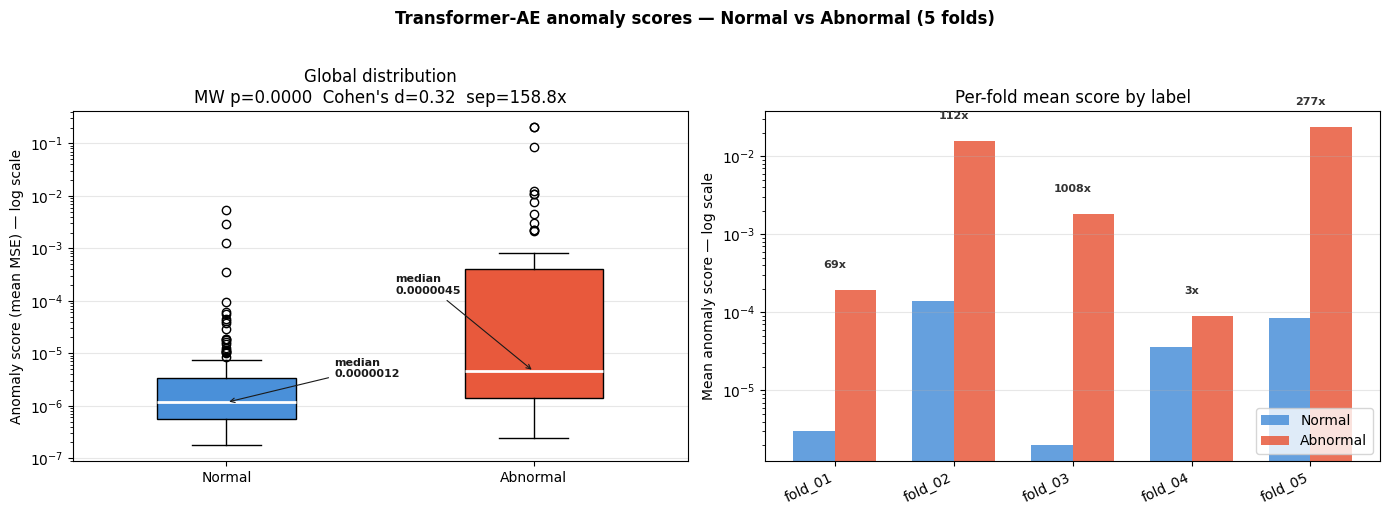

Saved.


<Figure size 640x480 with 0 Axes>

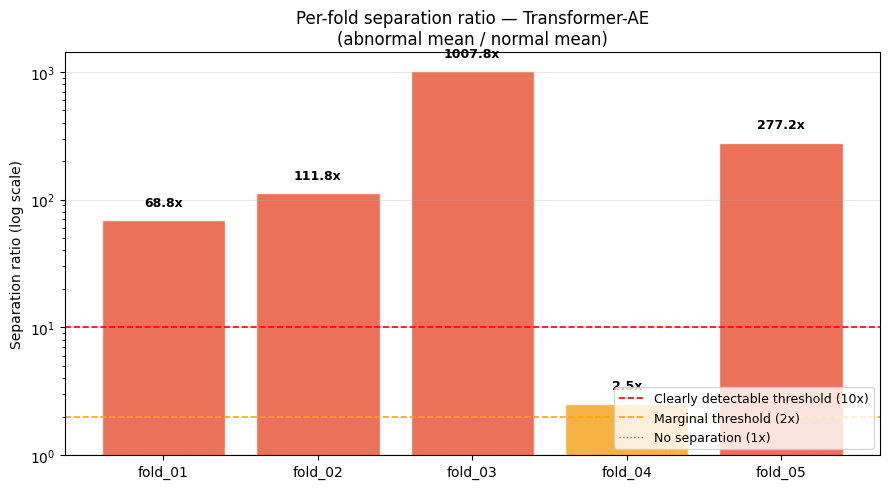

Saved.


<Figure size 640x480 with 0 Axes>

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# log-scale boxplot
bp = axes[0].boxplot(
    [normal, abnormal], tick_labels=['Normal', 'Abnormal'],
    patch_artist=True, notch=False, widths=0.45
)
bp['boxes'][0].set_facecolor('#4A90D9')
bp['boxes'][1].set_facecolor('#E8593C')
for median in bp['medians']:
    median.set_color('white')
    median.set_linewidth(2)

axes[0].set_yscale('log')
axes[0].set_ylabel('Anomaly score (mean MSE) — log scale')
axes[0].set_title(f'Global distribution\nMW p={p_val:.4f}  Cohen\'s d={d:.2f}  sep={sep_ratio:.1f}x')
axes[0].grid(True, alpha=0.3, axis='y')

# median labels
norm_med = np.median(normal)
abn_med  = np.median(abnormal)

axes[0].annotate(f'median\n{norm_med:.7f}',
                 xy=(1, norm_med), xytext=(1.35, norm_med * 3),
                 fontsize=8, fontweight='bold', color='#1a1a1a',
                 arrowprops=dict(arrowstyle='->', color='#1a1a1a', lw=0.8))

axes[0].annotate(f'median\n{abn_med:.7f}',
                 xy=(2, abn_med), xytext=(1.55, abn_med * 30),
                 fontsize=8, fontweight='bold', color='#1a1a1a',
                 arrowprops=dict(arrowstyle='->', color='#1a1a1a', lw=0.8))

# log-scale per-fold grouped bar
x       = np.arange(len(FOLDS))
w       = 0.35
n_means = df_fold_summary['Normal mean'].values
a_means = df_fold_summary['Abnormal mean'].values
sep     = df_fold_summary['Sep ratio'].values

axes[1].bar(x - w/2, n_means, w, label='Normal',   color='#4A90D9', alpha=0.85)
axes[1].bar(x + w/2, a_means, w, label='Abnormal', color='#E8593C', alpha=0.85)
axes[1].set_yscale('log')
axes[1].set_xticks(x)
axes[1].set_xticklabels(FOLDS, rotation=25, ha='right')
axes[1].set_ylabel('Mean anomaly score — log scale')
axes[1].set_title('Per-fold mean score by label')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.3, axis='y')

# sep ratio inside plot area
for i, (nm, am, s) in enumerate(zip(n_means, a_means, sep)):
    top = max(nm, am) * 1.8
    axes[1].text(i, top, f'{s:.0f}x',
                 ha='center', va='bottom', fontsize=8,
                 fontweight='bold', color='#333333')

plt.suptitle('Transformer-AE anomaly scores — Normal vs Abnormal (5 folds)',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
plt.savefig(OUT_DIR / 'anomaly_score_distribution.png', dpi=150, bbox_inches='tight')
print('Saved.')
#per-fold sep ratio bar
fig, ax = plt.subplots(figsize=(9, 5))

sep_vals = df_fold_summary['Sep ratio'].values
colors   = ['#E8593C' if s >= 10 else '#F5A623' if s >= 2 else '#4A90D9'
            for s in sep_vals]

ax.bar(FOLDS, sep_vals, color=colors, alpha=0.85, edgecolor='white')
ax.set_yscale('log')
ax.axhline(10, color='red',    linestyle='--', linewidth=1.2,
           label='Clearly detectable threshold (10x)')
ax.axhline(2,  color='orange', linestyle='--', linewidth=1.2,
           label='Marginal threshold (2x)')
ax.axhline(1,  color='gray',   linestyle=':',  linewidth=1.0,
           label='No separation (1x)')

for i, s in enumerate(sep_vals):
    ax.text(i, s * 1.3, f'{s:.1f}x', ha='center', fontsize=9, fontweight='bold')

ax.set_ylabel('Separation ratio (log scale)')
ax.set_title('Per-fold separation ratio — Transformer-AE\n'
             '(abnormal mean / normal mean)')
ax.legend(loc='lower right', fontsize=9)
ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim(bottom=1)

plt.tight_layout()
plt.show()
plt.savefig(OUT_DIR / 'separation_ratio_per_fold.png', dpi=150, bbox_inches='tight')
print('Saved.')

In [7]:
# --------------------------------------------------
# Recreate per-fold summary from saved anomaly scores
# --------------------------------------------------

FOLDS = [f"fold_{i:02d}" for i in range(1, 6)]

# Make sure labels are consistent
df_plot["label_name"] = (
    df_plot["dataset_label"]
    .astype(str)
    .str.lower()
    .map({
        "normal": "Normal",
        "abnormal": "Abnormal"
    })
)

fold_rows = []

for fold in FOLDS:

    fold_df = df_plot[df_plot["fold"] == fold]

    normal_scores = fold_df.loc[
        fold_df["label_name"] == "Normal",
        "anomaly_score"
    ].dropna()

    abnormal_scores = fold_df.loc[
        fold_df["label_name"] == "Abnormal",
        "anomaly_score"
    ].dropna()

    normal_mean = normal_scores.mean()
    abnormal_mean = abnormal_scores.mean()

    sep_ratio_fold = (
        abnormal_mean / normal_mean
        if normal_mean > 0 else np.nan
    )

    fold_rows.append({
        "Fold": fold,
        "Normal mean": normal_mean,
        "Abnormal mean": abnormal_mean,
        "Sep ratio": sep_ratio_fold
    })

df_fold_summary = pd.DataFrame(fold_rows)

print(df_fold_summary)

      Fold  Normal mean  Abnormal mean    Sep ratio
0  fold_01     0.000003       0.000193    68.783891
1  fold_02     0.000141       0.015810   111.797687
2  fold_03     0.000002       0.001810  1007.779738
3  fold_04     0.000036       0.000091     2.534715
4  fold_05     0.000085       0.023617   277.155100



Per-fold summary:
      Fold  Normal mean  Abnormal mean    Sep ratio
0  fold_01     0.000003       0.000193    68.783891
1  fold_02     0.000141       0.015810   111.797687
2  fold_03     0.000002       0.001810  1007.779738
3  fold_04     0.000036       0.000091     2.534715
4  fold_05     0.000085       0.023617   277.155100

Mann–Whitney p-value: 1.09705e-07
Cohen's d: 0.324
Global mean separation: 158.8×


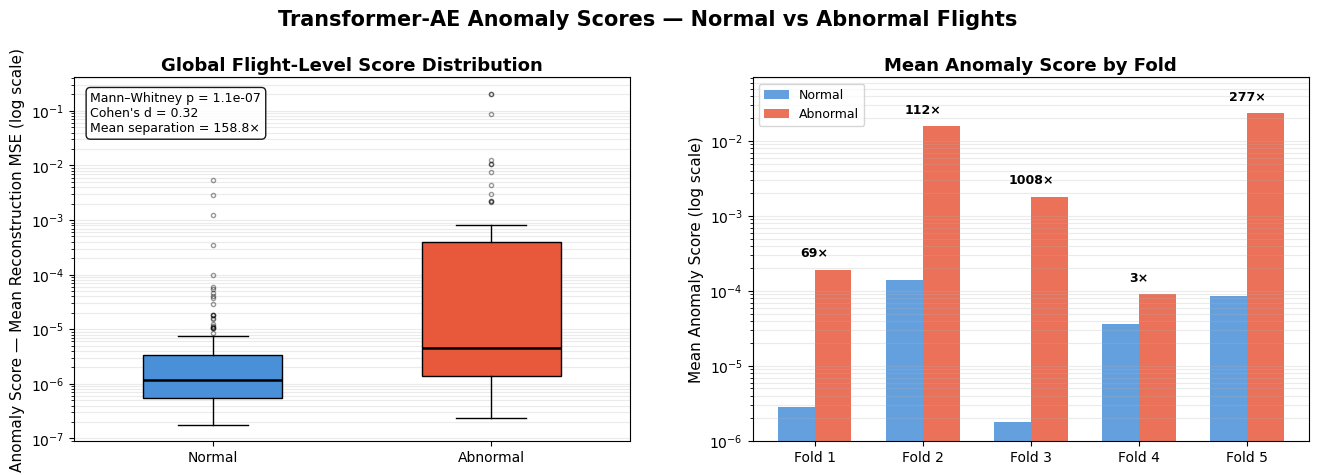

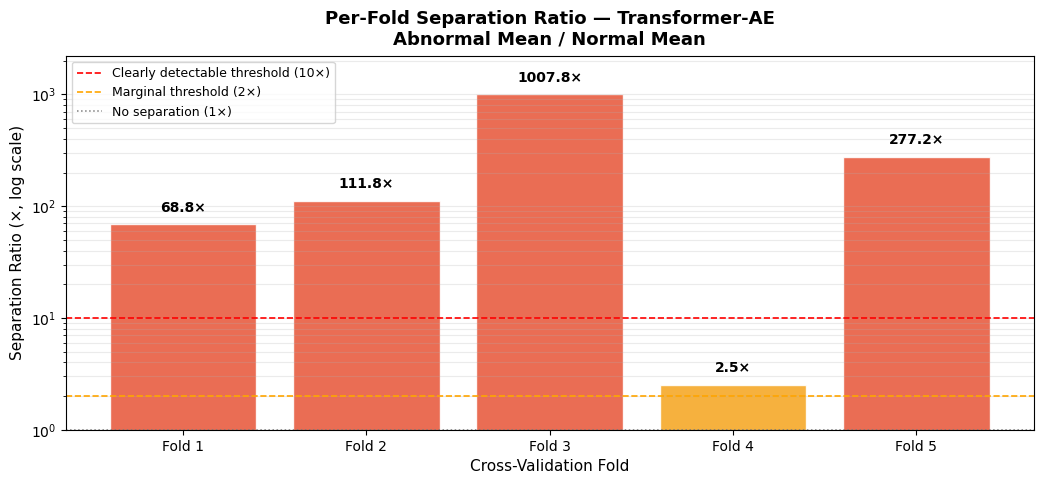


Both thesis-ready figures saved successfully.


In [9]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


# ============================================================
# PREPARE SAVED ANOMALY-SCORE DATA
# ============================================================

FOLDS = [f"fold_{i:02d}" for i in range(1, 6)]

# Standardise labels
df_plot = df_plot.copy()

df_plot["label_name"] = (
    df_plot["dataset_label"]
    .astype(str)
    .str.lower()
    .map({
        "normal": "Normal",
        "abnormal": "Abnormal"
    })
)

# Keep valid positive scores for log-scale plotting
df_plot = df_plot.dropna(
    subset=["label_name", "anomaly_score", "fold"]
).copy()

df_plot = df_plot[
    df_plot["anomaly_score"] > 0
].copy()


# Global normal and abnormal score arrays
normal = df_plot.loc[
    df_plot["label_name"] == "Normal",
    "anomaly_score"
].values

abnormal = df_plot.loc[
    df_plot["label_name"] == "Abnormal",
    "anomaly_score"
].values


# ============================================================
# GLOBAL STATISTICS
# ============================================================

_, p_val = stats.mannwhitneyu(
    abnormal,
    normal,
    alternative="greater"
)

pooled_std = np.sqrt(
    (
        normal.std(ddof=1) ** 2
        + abnormal.std(ddof=1) ** 2
    ) / 2
)

d = (
    (abnormal.mean() - normal.mean()) / pooled_std
    if pooled_std > 0 else np.nan
)

sep_ratio = (
    abnormal.mean() / normal.mean()
    if normal.mean() > 0 else np.nan
)


# ============================================================
# PER-FOLD SUMMARY
# ============================================================

fold_rows = []

for fold in FOLDS:

    fold_df = df_plot[
        df_plot["fold"] == fold
    ]

    normal_scores = fold_df.loc[
        fold_df["label_name"] == "Normal",
        "anomaly_score"
    ]

    abnormal_scores = fold_df.loc[
        fold_df["label_name"] == "Abnormal",
        "anomaly_score"
    ]

    normal_mean = normal_scores.mean()
    abnormal_mean = abnormal_scores.mean()

    fold_sep_ratio = (
        abnormal_mean / normal_mean
        if normal_mean > 0 else np.nan
    )

    fold_rows.append({
        "Fold": fold,
        "Normal mean": normal_mean,
        "Abnormal mean": abnormal_mean,
        "Sep ratio": fold_sep_ratio
    })

df_fold_summary = pd.DataFrame(fold_rows)

print("\nPer-fold summary:")
print(df_fold_summary)

print(f"\nMann–Whitney p-value: {p_val:.6g}")
print(f"Cohen's d: {d:.3f}")
print(f"Global mean separation: {sep_ratio:.1f}×")


# ============================================================
# FIGURE 3.11
# Transformer-AE anomaly scores: Normal vs Abnormal
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(13.5, 5.2)
)

fig.suptitle(
    "Transformer-AE Anomaly Scores — Normal vs Abnormal Flights",
    fontsize=15,
    fontweight="bold",
    y=0.97
)


# ------------------------------------------------------------
# Left panel — global flight-level distribution
# ------------------------------------------------------------

bp = axes[0].boxplot(
    [normal, abnormal],
    tick_labels=["Normal", "Abnormal"],
    patch_artist=True,
    notch=False,
    widths=0.5,
    flierprops=dict(
        marker="o",
        markersize=3,
        alpha=0.4
    )
)

bp["boxes"][0].set_facecolor("#4A90D9")
bp["boxes"][1].set_facecolor("#E8593C")

for median in bp["medians"]:
    median.set_color("black")
    median.set_linewidth(1.8)

axes[0].set_yscale("log")

axes[0].set_title(
    "Global Flight-Level Score Distribution",
    fontsize=13,
    fontweight="bold",
    pad=5
)

axes[0].set_ylabel(
    "Anomaly Score — Mean Reconstruction MSE (log scale)",
    fontsize=11
)

axes[0].tick_params(
    axis="both",
    labelsize=10
)

axes[0].grid(
    True,
    alpha=0.25,
    axis="y",
    which="both"
)

# Statistical summary box
axes[0].text(
    0.03,
    0.96,
    f"Mann–Whitney p = {p_val:.3g}\n"
    f"Cohen's d = {d:.2f}\n"
    f"Mean separation = {sep_ratio:.1f}×",
    transform=axes[0].transAxes,
    va="top",
    fontsize=9,
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        alpha=0.9
    )
)


# ------------------------------------------------------------
# Right panel — per-fold mean anomaly scores
# ------------------------------------------------------------

x = np.arange(len(FOLDS))
width = 0.34

n_means = df_fold_summary["Normal mean"].values
a_means = df_fold_summary["Abnormal mean"].values
sep = df_fold_summary["Sep ratio"].values

axes[1].bar(
    x - width / 2,
    n_means,
    width,
    label="Normal",
    color="#4A90D9",
    alpha=0.85
)

axes[1].bar(
    x + width / 2,
    a_means,
    width,
    label="Abnormal",
    color="#E8593C",
    alpha=0.85
)

axes[1].set_yscale("log")

axes[1].set_title(
    "Mean Anomaly Score by Fold",
    fontsize=13,
    fontweight="bold",
    pad=5
)

axes[1].set_ylabel(
    "Mean Anomaly Score (log scale)",
    fontsize=11
)

axes[1].set_xticks(x)

axes[1].set_xticklabels(
    [f"Fold {i}" for i in range(1, 6)],
    fontsize=10
)

axes[1].tick_params(
    axis="y",
    labelsize=10
)

axes[1].legend(
    loc="upper left",
    fontsize=9,
    frameon=True
)

axes[1].grid(
    True,
    alpha=0.25,
    axis="y",
    which="both"
)

# Separation-ratio labels
for i, (normal_mean, abnormal_mean, ratio) in enumerate(
    zip(n_means, a_means, sep)
):

    top = max(normal_mean, abnormal_mean)

    axes[1].text(
        i,
        top * 1.35,
        f"{ratio:.0f}×",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

# Provide enough headroom
highest_bar = max(
    n_means.max(),
    a_means.max()
)

lowest_bar = min(
    n_means.min(),
    a_means.min()
)

axes[1].set_ylim(
    bottom=lowest_bar * 0.55,
    top=highest_bar * 3.0
)


# Compact layout
fig.subplots_adjust(
    left=0.075,
    right=0.99,
    bottom=0.14,
    top=0.84,
    wspace=0.22
)

plt.savefig(
    OUT_DIR / "anomaly_score_distribution_thesis.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.03
)

plt.show()
plt.close()


# ============================================================
# FIGURE 3.12
# Per-fold Transformer-AE separation ratio
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 5.5)
)

sep_vals = df_fold_summary["Sep ratio"].values

# Colour based on detectability level
colors = [
    "#E8593C" if s >= 10
    else "#F5A623" if s >= 2
    else "#4A90D9"
    for s in sep_vals
]

fold_labels = [
    f"Fold {i}"
    for i in range(1, 6)
]

ax.bar(
    fold_labels,
    sep_vals,
    color=colors,
    alpha=0.88,
    edgecolor="white",
    linewidth=1
)

ax.set_yscale("log")


# ------------------------------------------------------------
# Detection reference lines
# ------------------------------------------------------------

ax.axhline(
    10,
    color="red",
    linestyle="--",
    linewidth=1.2,
    label="Clearly detectable threshold (10×)"
)

ax.axhline(
    2,
    color="orange",
    linestyle="--",
    linewidth=1.2,
    label="Marginal threshold (2×)"
)

ax.axhline(
    1,
    color="gray",
    linestyle=":",
    linewidth=1.1,
    label="No separation (1×)"
)


# ------------------------------------------------------------
# Ratio labels above bars
# ------------------------------------------------------------

for i, ratio in enumerate(sep_vals):

    ax.text(
        i,
        ratio * 1.22,
        f"{ratio:.1f}×",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )


# ------------------------------------------------------------
# Labels and title
# ------------------------------------------------------------

ax.set_ylabel(
    "Separation Ratio (×, log scale)",
    fontsize=11
)

ax.set_xlabel(
    "Cross-Validation Fold",
    fontsize=11
)

ax.set_title(
    "Per-Fold Separation Ratio — Transformer-AE\n"
    "Abnormal Mean / Normal Mean",
    fontsize=13,
    fontweight="bold",
    pad=8
)

ax.tick_params(
    axis="x",
    labelsize=10
)

ax.tick_params(
    axis="y",
    labelsize=10
)

ax.grid(
    True,
    alpha=0.25,
    axis="y",
    which="both"
)

# Legend positioned away from the bars
ax.legend(
    loc="upper left",
    fontsize=9,
    frameon=True
)

# Enough room for Fold 3 label
ax.set_ylim(
    bottom=1,
    top=max(sep_vals) * 2.2
)

fig.subplots_adjust(
    left=0.10,
    right=0.98,
    bottom=0.15,
    top=0.83
)

plt.savefig(
    OUT_DIR / "separation_ratio_per_fold_thesis.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.03
)

plt.show()
plt.close()

print("\nBoth thesis-ready figures saved successfully.")

Loaded: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/processed_10hz/v2/v3b/07_anomaly_enriched/oof_and_test_anomaly_scores.parquet
Shape: (270, 7)
fold     split
fold_01  test     34
         val      20
fold_02  test     34
         val      20
fold_03  test     33
         val      21
fold_04  test     33
         val      21
fold_05  test     33
         val      21
dtype: int64

Per-fold summary:
      fold  normal_mean  abnormal_mean    sep_ratio
0  fold_01     0.000003       0.000193    68.783891
1  fold_02     0.000141       0.015810   111.797687
2  fold_03     0.000002       0.001810  1007.779738
3  fold_04     0.000036       0.000091     2.534715
4  fold_05     0.000085       0.023617   277.155100


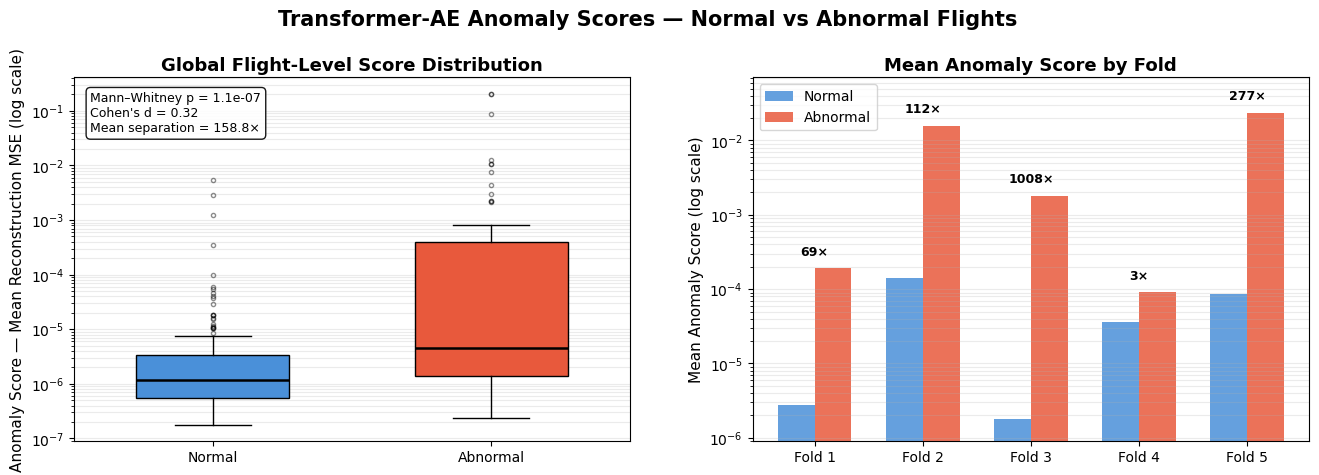


Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/processed_10hz/v2/v3b/07_anomaly_enriched/anomaly_score_distribution_thesis.png


In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# --------------------------------------------------
# Exact v3b saved anomaly-score file
# --------------------------------------------------

PROJECT_DIR = Path(
    "/Users/arjun/Documents/UAV thesis/uav-thesis/"
    "uav_px4_dataset_project"
)

OUT_DIR = (
    PROJECT_DIR
    / "processed_10hz"
    / "v2"
    / "v3b"
    / "07_anomaly_enriched"
)

scores_path = OUT_DIR / "oof_and_test_anomaly_scores.parquet"

# Load already-computed flight-level scores
df_plot = pd.read_parquet(scores_path)

print("Loaded:", scores_path)
print("Shape:", df_plot.shape)
print(df_plot.groupby(["fold", "split"]).size())


# --------------------------------------------------
# Prepare labels
# --------------------------------------------------

df_plot = df_plot.dropna(
    subset=["dataset_label", "anomaly_score"]
).copy()

df_plot["label_name"] = (
    df_plot["dataset_label"]
    .astype(str)
    .str.lower()
    .map({
        "normal": "Normal",
        "abnormal": "Abnormal"
    })
)

# Remove any non-positive values before log plotting
df_plot = df_plot[
    df_plot["anomaly_score"] > 0
].copy()

FOLDS = [
    "fold_01",
    "fold_02",
    "fold_03",
    "fold_04",
    "fold_05"
]

normal = df_plot.loc[
    df_plot["label_name"] == "Normal",
    "anomaly_score"
].values

abnormal = df_plot.loc[
    df_plot["label_name"] == "Abnormal",
    "anomaly_score"
].values


# --------------------------------------------------
# Overall statistics
# --------------------------------------------------

normal_mean = normal.mean()
abnormal_mean = abnormal.mean()

normal_median = np.median(normal)
abnormal_median = np.median(abnormal)

global_sep = abnormal_mean / normal_mean

_, p_value = stats.mannwhitneyu(
    abnormal,
    normal,
    alternative="greater"
)

pooled_std = np.sqrt(
    (
        normal.std(ddof=1) ** 2
        + abnormal.std(ddof=1) ** 2
    ) / 2
)

cohens_d = (
    (abnormal_mean - normal_mean) / pooled_std
    if pooled_std > 0 else np.nan
)


# --------------------------------------------------
# Per-fold summary
# --------------------------------------------------

fold_rows = []

for fold in FOLDS:

    fd = df_plot[df_plot["fold"] == fold]

    n = fd.loc[
        fd["label_name"] == "Normal",
        "anomaly_score"
    ].values

    a = fd.loc[
        fd["label_name"] == "Abnormal",
        "anomaly_score"
    ].values

    n_mean = n.mean()
    a_mean = a.mean()

    fold_rows.append({
        "fold": fold,
        "normal_mean": n_mean,
        "abnormal_mean": a_mean,
        "sep_ratio": a_mean / n_mean
    })

fold_summary = pd.DataFrame(fold_rows)

print("\nPer-fold summary:")
print(fold_summary)


# --------------------------------------------------
# Thesis-ready Figure 3.11
# --------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(13.5, 5.2)
)

fig.suptitle(
    "Transformer-AE Anomaly Scores — Normal vs Abnormal Flights",
    fontsize=15,
    fontweight="bold",
    y=0.97
)


# --------------------------------------------------
# LEFT PANEL — global score distribution
# --------------------------------------------------

bp = axes[0].boxplot(
    [normal, abnormal],
    tick_labels=["Normal", "Abnormal"],
    patch_artist=True,
    widths=0.55,
    showfliers=True,
    flierprops=dict(
        marker="o",
        markersize=3,
        alpha=0.45
    )
)

bp["boxes"][0].set_facecolor("#4A90D9")
bp["boxes"][1].set_facecolor("#E8593C")

for median_line in bp["medians"]:
    median_line.set_color("black")
    median_line.set_linewidth(1.8)

axes[0].set_yscale("log")

axes[0].set_title(
    "Global Flight-Level Score Distribution",
    fontsize=13,
    fontweight="bold",
    pad=5
)

axes[0].set_ylabel(
    "Anomaly Score — Mean Reconstruction MSE (log scale)",
    fontsize=11
)

axes[0].tick_params(
    axis="both",
    labelsize=10
)

axes[0].grid(
    True,
    alpha=0.25,
    axis="y",
    which="both"
)

# Compact statistical summary
axes[0].text(
    0.03,
    0.96,
    f"Mann–Whitney p = {p_value:.3g}\n"
    f"Cohen's d = {cohens_d:.2f}\n"
    f"Mean separation = {global_sep:.1f}×",
    transform=axes[0].transAxes,
    va="top",
    fontsize=9,
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        alpha=0.9
    )
)


# --------------------------------------------------
# RIGHT PANEL — per-fold mean scores
# --------------------------------------------------

x = np.arange(len(FOLDS))
width = 0.34

normal_means = fold_summary["normal_mean"].values
abnormal_means = fold_summary["abnormal_mean"].values
sep_ratios = fold_summary["sep_ratio"].values

axes[1].bar(
    x - width / 2,
    normal_means,
    width,
    label="Normal",
    color="#4A90D9",
    alpha=0.85
)

axes[1].bar(
    x + width / 2,
    abnormal_means,
    width,
    label="Abnormal",
    color="#E8593C",
    alpha=0.85
)

axes[1].set_yscale("log")

axes[1].set_title(
    "Mean Anomaly Score by Fold",
    fontsize=13,
    fontweight="bold",
    pad=5
)

axes[1].set_ylabel(
    "Mean Anomaly Score (log scale)",
    fontsize=11
)

axes[1].set_xticks(x)

axes[1].set_xticklabels(
    ["Fold 1", "Fold 2", "Fold 3", "Fold 4", "Fold 5"],
    fontsize=10
)

axes[1].tick_params(
    axis="y",
    labelsize=10
)

axes[1].legend(
    fontsize=10,
    loc="upper left"
)

axes[1].grid(
    True,
    alpha=0.25,
    axis="y",
    which="both"
)

# Separation-ratio labels
for i, (n_mean, a_mean, sep) in enumerate(
    zip(normal_means, abnormal_means, sep_ratios)
):
    top = max(n_mean, a_mean)

    axes[1].text(
        i,
        top * 1.35,
        f"{sep:.0f}×",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

# Leave room above tallest ratio label
highest_bar = max(
    normal_means.max(),
    abnormal_means.max()
)

axes[1].set_ylim(
    bottom=min(
        normal_means.min(),
        abnormal_means.min()
    ) * 0.5,
    top=highest_bar * 3
)


# --------------------------------------------------
# Compact layout and 300-dpi export
# --------------------------------------------------

fig.subplots_adjust(
    left=0.075,
    right=0.99,
    bottom=0.14,
    top=0.84,
    wspace=0.22
)

plt.savefig(
    OUT_DIR / "anomaly_score_distribution_thesis.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.03
)

plt.show()
plt.close()

print(
    "\nSaved:",
    OUT_DIR / "anomaly_score_distribution_thesis.png"
)

In [18]:
# inspect raw score distribution before aggregation
state = torch.load(AE_DIR / 'transformer_ae_fold_01.pt', map_location='cpu')

# load fold_01 and score a few flights manually
fold_dir = OUTPUT_ROOT / 'fold_01'
suffix   = 'v5_voltage_kfold5_fold_01'
df_test  = pd.read_parquet(fold_dir / f'test_no_dr_scaled_{suffix}.parquet')

with open(fold_dir / 'feature_cols_fold_01.json') as f:
    feature_cols = json.load(f)

model = TransformerAutoencoder(n_features=16).to(DEVICE)
model.load_state_dict(torch.load(AE_DIR / 'transformer_ae_fold_01.pt', map_location=DEVICE))
model.eval()

# score first 5 flights and print raw MSE
for fid, grp in list(df_test.groupby('log_id'))[:5]:
    X = grp[feature_cols].values.astype(np.float32)
    windows = []
    for start in range(0, len(X) - 100 + 1, 10):
        windows.append(X[start:start+100])
    wt = torch.tensor(np.stack(windows)).to(DEVICE)
    with torch.no_grad():
        recon = model(wt)
    mse = ((wt - recon)**2).mean(dim=(1,2)).cpu().numpy()
    label = grp['dataset_label'].iloc[0]
    print(f'{fid[:8]} | {label:8s} | mean_mse={mse.mean():.8f} | min={mse.min():.8f} | max={mse.max():.8f}')

022107fb | normal   | mean_mse=0.00000028 | min=0.00000020 | max=0.00000070
0d64166c | normal   | mean_mse=0.00000031 | min=0.00000020 | max=0.00000218
13efd310 | abnormal | mean_mse=0.00001269 | min=0.00000307 | max=0.00006246
14332f0c | normal   | mean_mse=0.00000024 | min=0.00000016 | max=0.00000091
160089e9 | normal   | mean_mse=0.00000045 | min=0.00000032 | max=0.00000088


In [19]:
# quick sanity — manually compute flight scores same way as above
# and compare to what score_split returned

fold_dir = OUTPUT_ROOT / 'fold_01'
suffix   = 'v5_voltage_kfold5_fold_01'
df_test  = pd.read_parquet(fold_dir / f'test_no_dr_scaled_{suffix}.parquet')

with open(fold_dir / 'feature_cols_fold_01.json') as f:
    feature_cols = json.load(f)

manual_scores = {}
for fid, grp in df_test.groupby('log_id'):
    X = grp[feature_cols].values.astype(np.float32)
    windows = []
    for start in range(0, len(X) - 100 + 1, 10):
        windows.append(X[start:start+100])
    wt = torch.tensor(np.stack(windows)).to(DEVICE)
    with torch.no_grad():
        recon = model(wt)
    mse = ((wt - recon)**2).mean(dim=(1,2)).cpu().numpy()
    label = grp['dataset_label'].iloc[0]
    manual_scores[fid] = {'score': mse.mean(), 'label': label}

manual_df = pd.DataFrame(manual_scores).T.reset_index()
manual_df.columns = ['log_id', 'score', 'label']
manual_df['score'] = manual_df['score'].astype(float)

print('Normal mean  :', manual_df[manual_df['label']=='normal']['score'].mean())
print('Abnormal mean:', manual_df[manual_df['label']=='abnormal']['score'].mean())
print('\nPer flight:')
print(manual_df.sort_values('score', ascending=False)[['log_id','label','score']].to_string(index=False))

Normal mean  : 3.0792818862962053e-06
Abnormal mean: 0.00031263655924718137

Per flight:
                              log_id    label        score
a3363780-8647-4341-a38a-77176235cdf2 abnormal 2.149147e-03
25c37f03-8611-4026-bb3a-ae908b19fb71 abnormal 3.192870e-04
83b00da7-f696-4af4-b3b7-f768fead3c7f   normal 4.094702e-05
670aaff6-ba17-4047-ae2c-53e26d74bf74   normal 1.790309e-05
d2dc82d7-0024-4562-b8dc-2edf5e4bbf22 abnormal 1.577290e-05
13efd310-a978-497d-8360-cc5b7b4a7d1a abnormal 1.269369e-05
e4c9925e-ebc8-4e02-aab3-da50ed1f8891   normal 3.011583e-06
d5fdc214-a392-42a1-9339-bb804e8f6af2   normal 2.421956e-06
25b9904e-0cf3-4ec7-aa78-48ee664818e4   normal 2.196410e-06
1dffb068-95fb-427c-9b3f-eba9ab6b9052   normal 2.145112e-06
7f74d2ab-19eb-4211-9993-663a7e5f1d84   normal 2.025223e-06
cb358ec1-2de5-4ff3-97c4-4d02f939cc39 abnormal 1.975507e-06
88f7d5ba-9eda-4e38-85ef-00d869562cab   normal 1.937013e-06
d22e643a-8935-4717-a194-04cc834630fe abnormal 1.459192e-06
d6b76077-5896-4e81-a966-8e

In [21]:
for fold in ['fold_01', 'fold_02', 'fold_03']:
    df = pd.read_parquet(ENRICHED_DIR / f'train_enriched_{fold}.parquet')
    pct_zero = (df['anomaly_score'] == 0).mean()
    print(f'{fold} | zeros={pct_zero:.1%} | '
          f'min={df["anomaly_score"].min():.4f} | '
          f'max={df["anomaly_score"].max():.4f} | '
          f'mean={df["anomaly_score"].mean():.4f}')

fold_01 | zeros=0.6% | min=0.0000 | max=1.0000 | mean=0.0770
fold_02 | zeros=0.6% | min=0.0000 | max=1.0000 | mean=0.1339
fold_03 | zeros=0.6% | min=0.0000 | max=1.0000 | mean=0.1273
